# Clustering de documents

## Imports

In [1]:
import collections
import os
import string
import sys

import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

In [2]:
import nltk

nltk.download('punkt')
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to C:\Users\COMPUTER
[nltk_data]     STORES\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\COMPUTER
[nltk_data]     STORES\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


True

In [3]:
data_path = "../../data/txt/"

## Choisir une décennie

In [4]:
DECADE = '1960'

## Charger tous les  fichiers de la décennie et en créer une liste de textes

In [5]:
files = [f for f in sorted(os.listdir(data_path)) if f"_{DECADE[:-1]}" in f]

In [6]:
# Vérifier le nombre de fichiers retenus, au total et par année
print(len(files), "fichiers pour la décennie", DECADE)
print(collections.Counter(f.split("_")[2][:4] for f in files))

1000 fichiers pour la décennie 1960
Counter({'1960': 100, '1961': 100, '1962': 100, '1963': 100, '1964': 100, '1965': 100, '1966': 100, '1967': 100, '1968': 100, '1969': 100})


In [7]:
# Exemple de fichiers
files[:5]

['KB_JB838_1960-01-10_01-00018.txt',
 'KB_JB838_1960-01-12_01-00011.txt',
 'KB_JB838_1960-01-13_01-00009.txt',
 'KB_JB838_1960-01-21_01-00014.txt',
 'KB_JB838_1960-01-22_01-00015.txt']

In [8]:
texts = [open(data_path + f, "r", encoding="utf-8").read() for f in files]

In [9]:
# Exemple de textes
texts[0][:400]

"ia« le som ÏJsIne MéuhMrïiqii S.AT'BBirîï^^ J00, r. Merlu» Duché, Vllvorde ch. STENO-DACTYLO élément de let ordre, bilingue, bon- i ne rémunération. Situation d’avenir, i Candidat, A soumet par écrit 130221H PORTANTE 80C.BRUXELL0I8I cherche pour entrée Immédiate Secrétaire Sténo-Dactylo 3 françalee - 1 an d'expérience, al tuât h «table - semaine de 5 Jours. Ecrire é cur. vit et prêt Ag. Rossel 029"

## Vectoriser les documents à l'aide de TF-IDF

In [10]:
# Création d'une fonction de pré-traitement
def preprocessing(text, stem=True):
    """ Tokenize text and remove punctuation """
    text = text.translate(string.punctuation)
    tokens = word_tokenize(text)
    return tokens

### Instancier le modèle TF-IDF avec ses arguments

In [11]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

### Construire la matrice de vecteurs à l'aide de la fonction `fit_transform`

In [12]:
tfidf_vectors = vectorizer.fit_transform(texts)

c:\Users\COMPUTER STORES\Desktop\BLOC II\tac\.venv\Lib\site-packages\sklearn\feature_extraction\text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [13]:
# Détail de la matrice
tfidf_vectors

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 591789 stored elements and shape (1000, 2997)>

### Imprimer le vecteur tf-IDF du premier document

In [14]:
pd.Series(
    tfidf_vectors[0].toarray()[0],
    index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

rossel        0.429709
ecrire        0.290668
agence        0.286526
bilingue      0.195557
importante    0.172312
                ...   
000           0.000000
01            0.000000
02            0.000000
02-           0.000000
♦             0.000000
Length: 2997, dtype: float64

## Comprendre les vecteurs et leurs "distances"

In [15]:
cosine([1, 2, 3], [1, 2, 3])

np.float64(0.0)

In [16]:
cosine([1, 2, 3], [1, 2, 2])

np.float64(0.02004211298777725)

In [17]:
cosine([1, 2, 3], [2, 2, 2])

np.float64(0.07417990022744858)

### Tests sur nos documents

In [19]:
tfidf_array = tfidf_vectors.toarray()

In [20]:
# Vecteur du document 0
tfidf_array[0]

array([0., 0., 0., ..., 0., 0., 0.], shape=(2997,))

In [21]:
# Vecteur du document 1
tfidf_array[1]

array([0.        , 0.01042959, 0.        , ..., 0.0108481 , 0.01231879,
       0.        ], shape=(2997,))

In [22]:
cosine(tfidf_array[0], tfidf_array[1])

np.float64(0.962932573267357)

## Appliquer un algorithme de clustering sur les vecteurs TF-IDF des documents

Pour en savoir plus sur le KMeans clustering :
- https://medium.com/dataseries/k-means-clustering-explained-visually-in-5-minutes-b900cc69d175

### Définir un nombre de clusters

In [23]:
N_CLUSTERS = 5

### Instancier le modèle K-Means et ses arguments

In [24]:
km_model = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)

### Appliquer le clustering à l'aide de la fonction `fit_predict`

In [25]:
clusters = km_model.fit_predict(tfidf_vectors)

In [26]:
clustering = collections.defaultdict(list)

for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

In [27]:
pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1960-01-28_01-00021.txt',
               'KB_JB838_1960-01-31_01-00024.txt',
               'KB_JB838_1960-02-24_01-00020.txt',
               'KB_JB838_1960-02-26_01-00011.txt',
               'KB_JB838_1960-03-11_01-00022.txt',
               'KB_JB838_1960-04-01_01-00022.txt',
               'KB_JB838_1960-04-06_01-00023.txt',
               'KB_JB838_1960-05-28_01-00021.txt',
               'KB_JB838_1960-08-25_01-00021.txt',
               'KB_JB838_1960-09-02_01-00013.txt',
               'KB_JB838_1960-11-16_01-00022.txt',
               'KB_JB838_1961-01-05_01-00016.txt',
               'KB_JB838_1961-01-18_01-00023.txt',
               'KB_JB838_1961-02-11_01-00023.txt',
               'KB_JB838_1961-04-15_01-00020.txt',
               'KB_JB838_1961-04-20_01-00022.txt',
               'KB_JB838_1961-04-29_01-00022.txt',
               'KB_JB838_1961-05-03_01-00024.txt',
               'KB_JB838_1961-05-25_01-00023.txt',
               'KB_JB838_1961-0

In [28]:
# Nombre de documents dans chaque cluster
taille = collections.Counter(clusters)
for c in sorted(taille):
    print(f"Cluster {c} : {taille[c]} documents")

print()

# Les 10 mots les plus importants de chaque cluster
mots = vectorizer.get_feature_names_out()
for c in range(N_CLUSTERS):
    top = km_model.cluster_centers_[c].argsort()[::-1][:10]
    print(f"Cluster {c} : {', '.join(mots[i] for i in top)}")

Cluster 0 : 126 documents
Cluster 1 : 447 documents
Cluster 2 : 191 documents
Cluster 3 : 125 documents
Cluster 4 : 111 documents

Cluster 0 : cv, 1/2, z, 3/4, 1/4, ...., état, 58, 59, km
Cluster 1 : musique, ministre, film, président, madame, monsieur, théâtre, gouvernement, lieu, politique
Cluster 2 : dem, rossel, pr, ecrire, ag, bilingue, prés, vitae, agence, engage
Cluster 3 : app, villa, gar, m2, pr, terr, ét, louer, ares, jard
Cluster 4 : mn, 2., match, 3., division, course, équipe, bat, placés, championnat


## Visualiser les clusters

### Réduire les vecteurs à 2 dimensions à l'aide de l'algorithme PCA
Cette étape est nécessaire afin de visualiser les documents dans un espace 2D

https://fr.wikipedia.org/wiki/Analyse_en_composantes_principales

In [29]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

In [30]:
reduced_vectors[:10]

array([[ 0.49953456, -0.43925981],
       [-0.22905682,  0.00148802],
       [-0.27884399, -0.01526168],
       [ 0.28621553,  0.51677846],
       [ 0.30703708,  0.5192117 ],
       [-0.28965897, -0.09099086],
       [-0.04753621,  0.04047809],
       [-0.06159535,  0.11962888],
       [-0.22356663, -0.05232803],
       [-0.12214075,  0.07430892]])

### Générer le plot

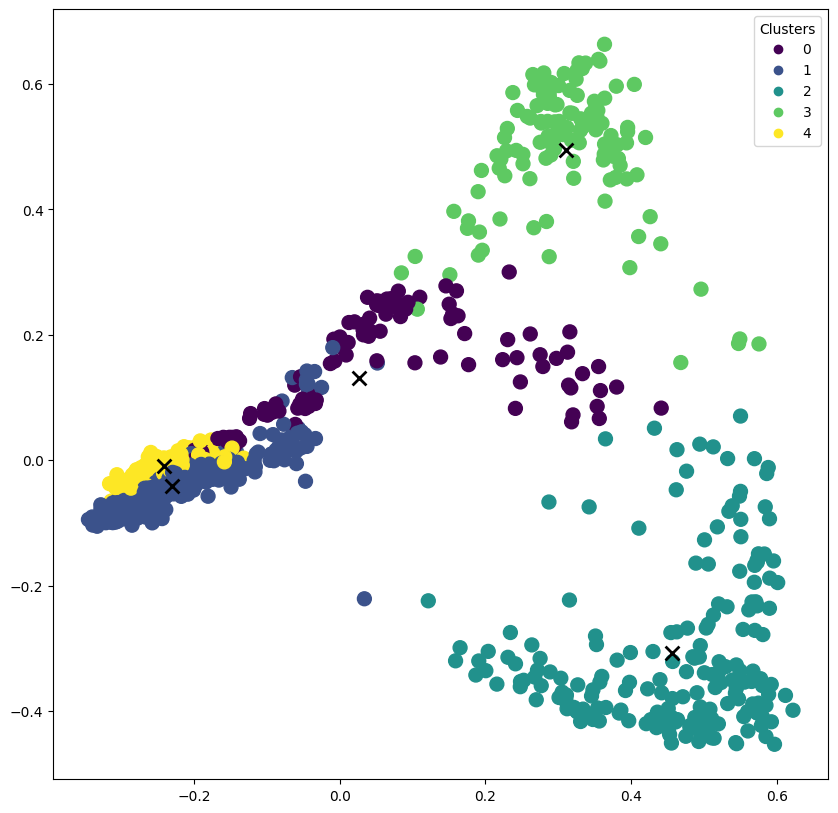

In [31]:
x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")

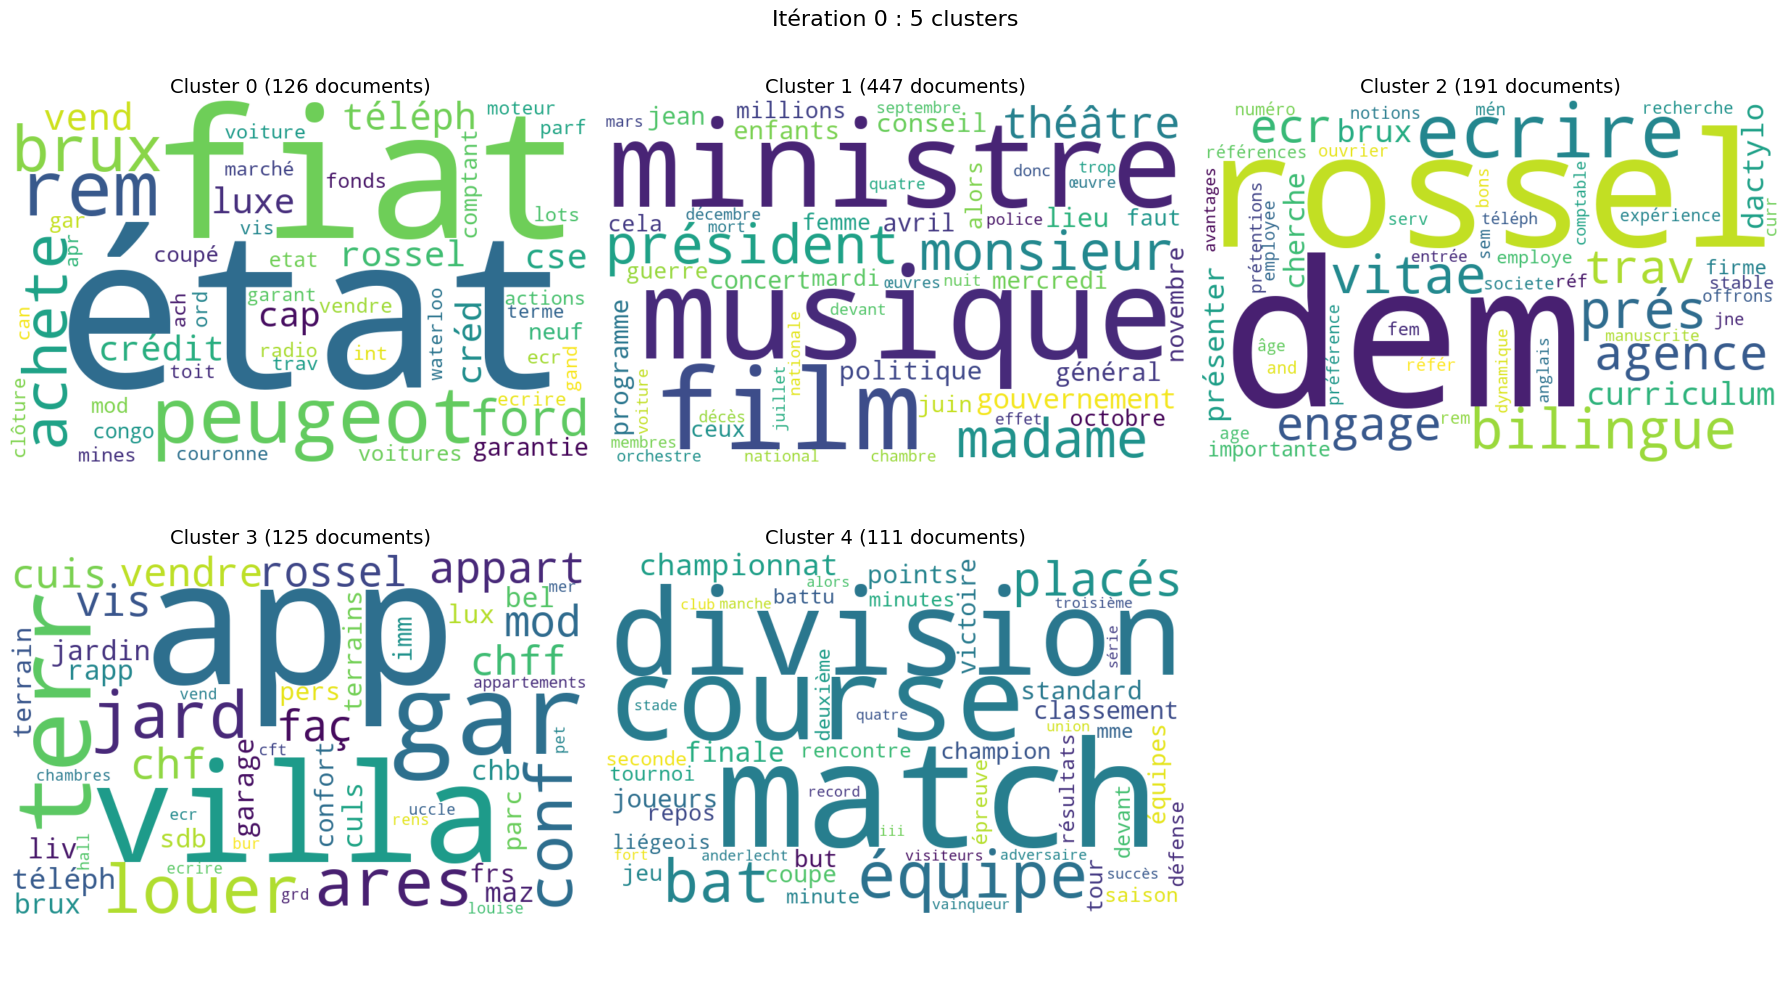

In [35]:
import math
from wordcloud import WordCloud

def nuages_clusters(modele, n_clusters, titre):
    """Dessine un nuage de mots par cluster, à partir des scores TF-IDF du centre du cluster."""
    mots = vectorizer.get_feature_names_out()
    n_col = 3
    n_lig = math.ceil(n_clusters / n_col)
    fig, axes = plt.subplots(n_lig, n_col, figsize=(18, 5 * n_lig))
    axes = axes.flatten()
    for c in range(n_clusters):
        centre = modele.cluster_centers_[c]
        # Garder seulement les vrais mots : des lettres uniquement, au moins 3 caractères
        poids = {mots[i]: centre[i] for i in centre.argsort()[::-1][:150]
                 if mots[i].isalpha() and len(mots[i]) > 2}
        nuage = WordCloud(width=800, height=500, background_color="white",
                          max_words=50).generate_from_frequencies(poids)
        axes[c].imshow(nuage, interpolation="bilinear")
        axes[c].set_title(f"Cluster {c} ({(modele.labels_ == c).sum()} documents)", fontsize=14)
        axes[c].axis("off")
    # Cacher les cases vides de la grille
    for c in range(n_clusters, len(axes)):
        axes[c].axis("off")
    fig.suptitle(titre, fontsize=16)
    plt.tight_layout()
    plt.show()

nuages_clusters(km_model, N_CLUSTERS, "Itération 0 : 5 clusters")

k =  2 | inertie =  790.9 | silhouette = 0.160
k =  3 | inertie =  738.9 | silhouette = 0.178
k =  4 | inertie =  710.9 | silhouette = 0.195
k =  5 | inertie =  681.3 | silhouette = 0.207
k =  6 | inertie =  658.1 | silhouette = 0.227
k =  7 | inertie =  640.7 | silhouette = 0.237
k =  8 | inertie =  615.2 | silhouette = 0.234
k =  9 | inertie =  597.8 | silhouette = 0.247
k = 10 | inertie =  586.1 | silhouette = 0.241
k = 11 | inertie =  571.9 | silhouette = 0.243
k = 12 | inertie =  562.2 | silhouette = 0.242


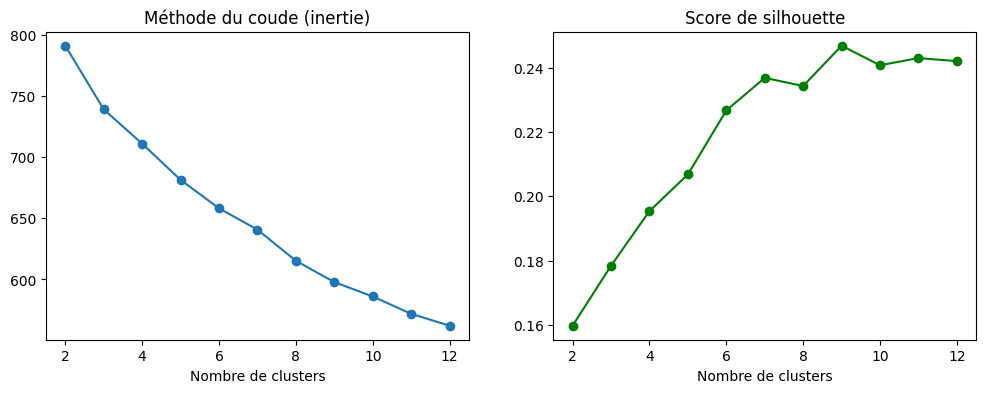

In [33]:
from sklearn.metrics import silhouette_score

# Tester K-Means avec 2 à 12 clusters et mesurer la qualité de chaque essai
resultats = []
for k in range(2, 13):
    modele = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquettes = modele.fit_predict(tfidf_vectors)
    silhouette = silhouette_score(tfidf_vectors, etiquettes, metric="cosine")
    resultats.append((k, modele.inertia_, silhouette))
    print(f"k = {k:2d} | inertie = {modele.inertia_:6.1f} | silhouette = {silhouette:.3f}")

# Dessiner les deux courbes côte à côte
ks = [r[0] for r in resultats]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, [r[1] for r in resultats], marker="o")
axes[0].set_title("Méthode du coude (inertie)")
axes[0].set_xlabel("Nombre de clusters")
axes[1].plot(ks, [r[2] for r in resultats], marker="o", color="green")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("Nombre de clusters")
plt.show()

In [36]:
# Comparer les deux candidats : 7 et 9 clusters
mots = vectorizer.get_feature_names_out()
modeles = {}
for k in [7, 9]:
    modele = KMeans(n_clusters=k, random_state=42, n_init=10)
    modele.fit(tfidf_vectors)
    modeles[k] = modele
    taille = collections.Counter(modele.labels_)
    print(f"===== {k} clusters =====")
    for c in range(k):
        top = modele.cluster_centers_[c].argsort()[::-1][:40]
        # Garder seulement les vrais mots, comme pour les nuages
        mots_c = [mots[i] for i in top if mots[i].isalpha() and len(mots[i]) > 2][:10]
        print(f"Cluster {c} ({taille[c]} docs) : {', '.join(mots_c)}")
    print()

===== 7 clusters =====
Cluster 0 (65 docs) : cap, clôture, comptant, terme, actions, marché, congo, tendance, mines, juillet
Cluster 1 (125 docs) : app, villa, gar, terr, louer, ares, jard, conf, appart, vis
Cluster 2 (150 docs) : musique, madame, monsieur, film, concert, programme, décès, théâtre, enfants, lieu
Cluster 3 (191 docs) : dem, rossel, ecrire, bilingue, prés, vitae, agence, engage, ecr, trav
Cluster 4 (284 docs) : ministre, président, gouvernement, politique, conseil, général, alors, cela, millions, voiture
Cluster 5 (109 docs) : match, division, équipe, course, bat, championnat, placés, finale, standard, joueurs
Cluster 6 (76 docs) : état, fiat, rem, peugeot, achete, téléph, luxe, brux, rossel, vend

===== 9 clusters =====
Cluster 0 (65 docs) : cap, clôture, comptant, terme, actions, marché, congo, tendance, mines, juillet
Cluster 1 (84 docs) : dem, prés, rossel, trav, brux, fem, ecrire, ecr, mén, présenter
Cluster 2 (111 docs) : match, division, course, équipe, bat, champ

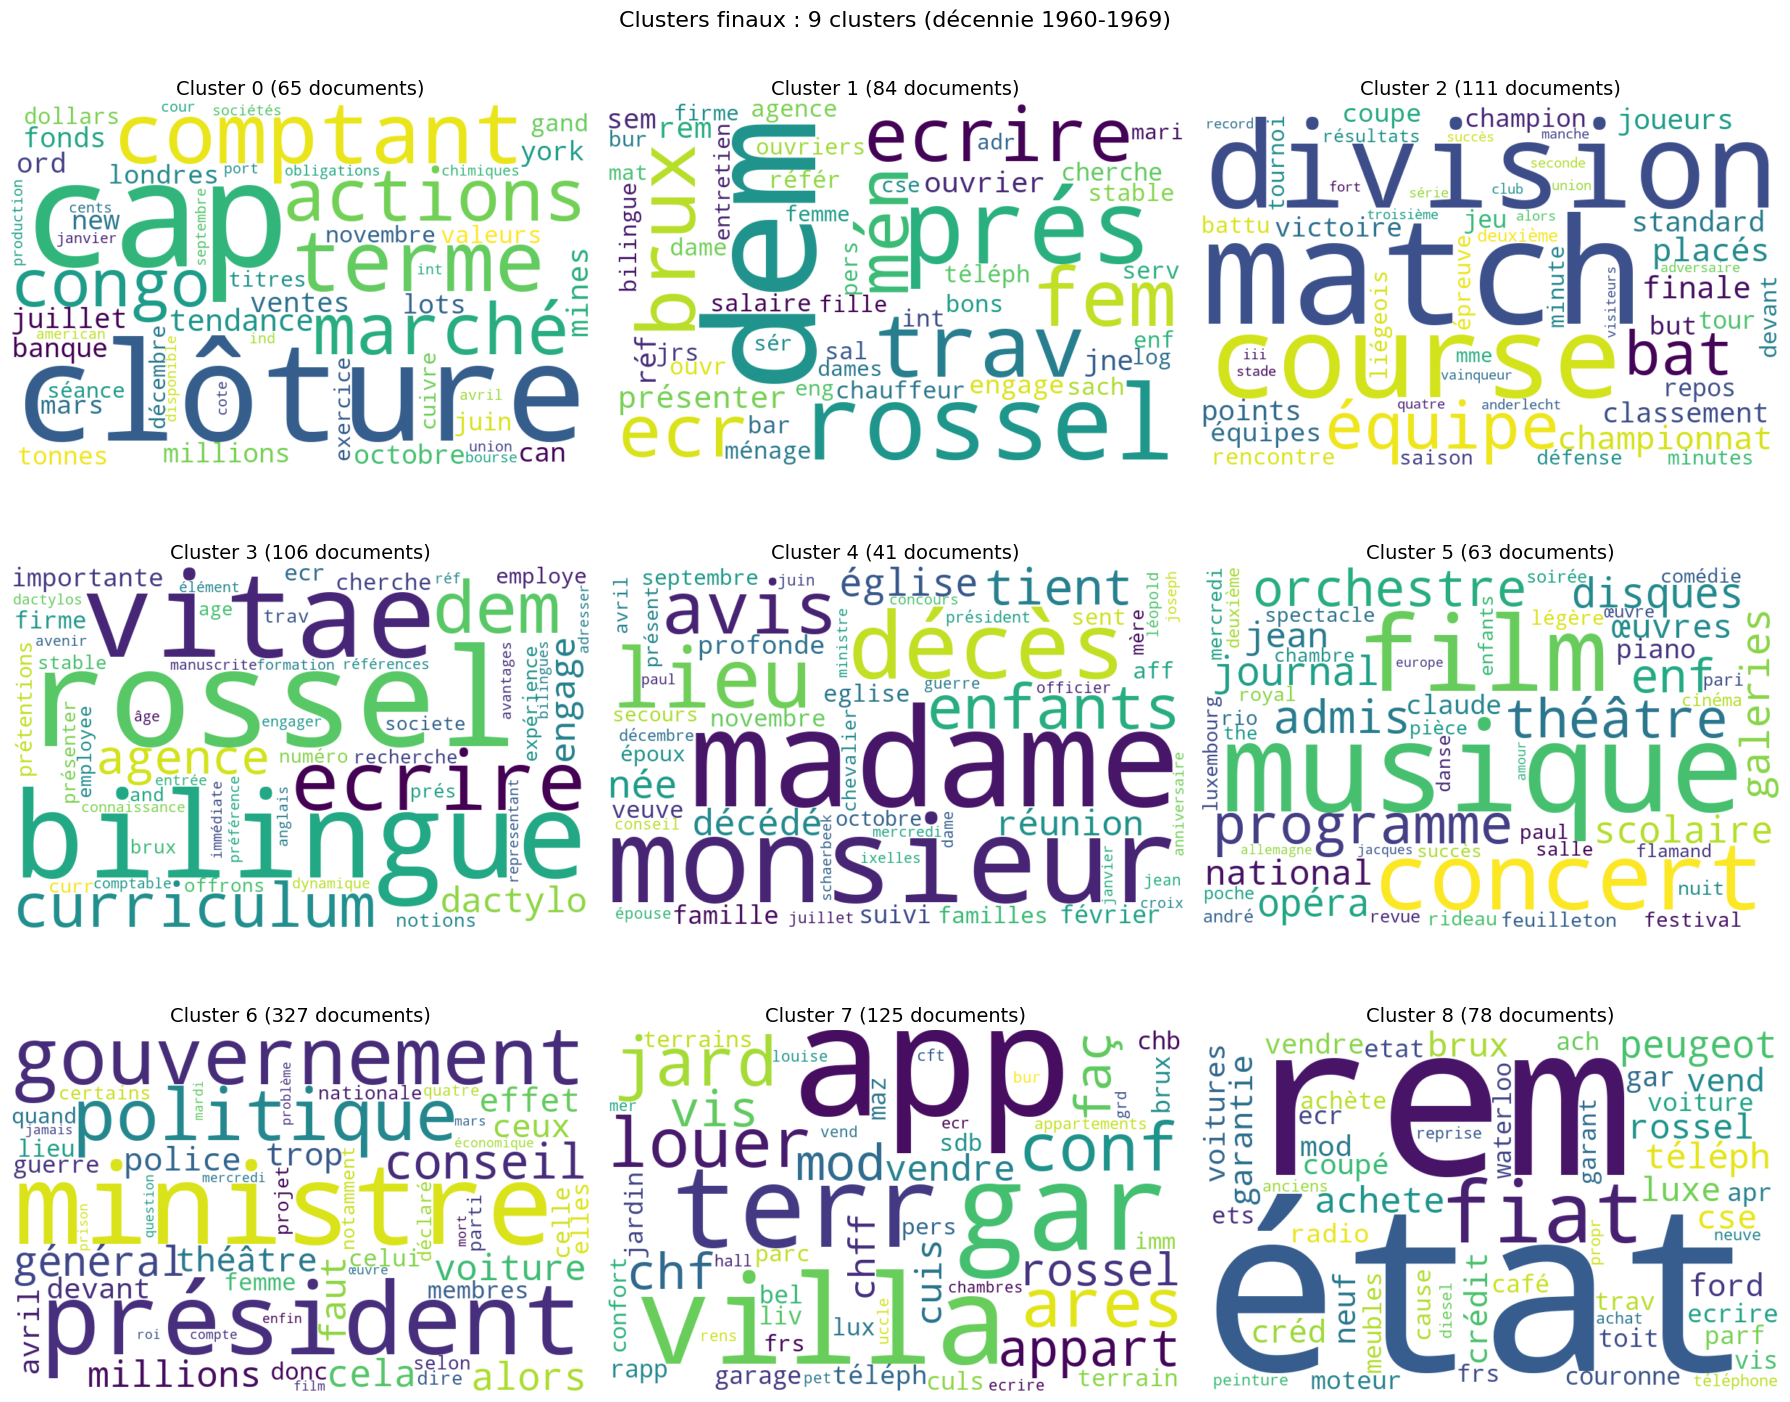

In [37]:
import math
from wordcloud import WordCloud

def nuages_clusters(modele, n_clusters, titre, fichier=None):
    """Dessine un nuage de mots par cluster, à partir des scores TF-IDF du centre du cluster."""
    mots = vectorizer.get_feature_names_out()
    n_col = 3
    n_lig = math.ceil(n_clusters / n_col)
    fig, axes = plt.subplots(n_lig, n_col, figsize=(18, 5 * n_lig))
    axes = axes.flatten()
    for c in range(n_clusters):
        centre = modele.cluster_centers_[c]
        # Garder seulement les vrais mots : des lettres uniquement, au moins 3 caractères
        poids = {mots[i]: centre[i] for i in centre.argsort()[::-1][:150]
                 if mots[i].isalpha() and len(mots[i]) > 2}
        nuage = WordCloud(width=800, height=500, background_color="white",
                          max_words=50).generate_from_frequencies(poids)
        axes[c].imshow(nuage, interpolation="bilinear")
        axes[c].set_title(f"Cluster {c} ({(modele.labels_ == c).sum()} documents)", fontsize=14)
        axes[c].axis("off")
    # Cacher les cases vides de la grille
    for c in range(n_clusters, len(axes)):
        axes[c].axis("off")
    fig.suptitle(titre, fontsize=16)
    plt.tight_layout()
    # Enregistrer l'image si un nom de fichier est donné
    if fichier:
        fig.savefig(fichier, dpi=150, bbox_inches="tight")
    plt.show()

# Nuages de mots des clusters finaux (9 clusters), enregistrés pour le rapport
nuages_clusters(modeles[9], 9, "Clusters finaux : 9 clusters (décennie 1960-1969)",
                fichier="nuages_clusters_1960.png")

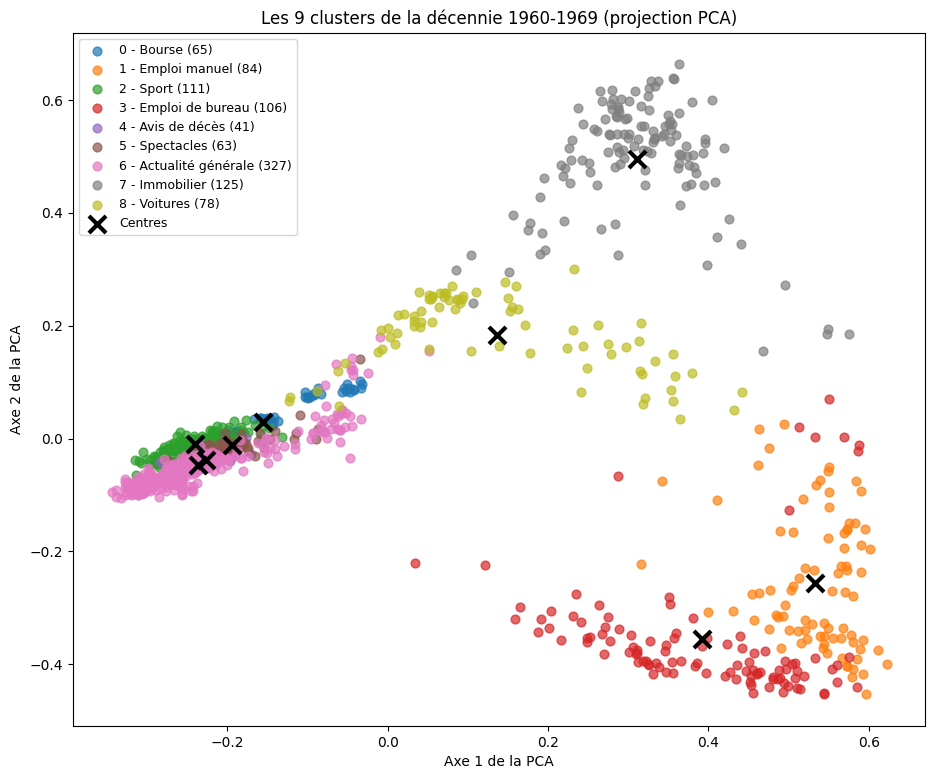

Part de l'information gardée par les 2 axes : 17.1%


In [38]:
# Visualiser les 9 clusters finaux en 2 dimensions (PCA)
noms = {0: "Bourse", 1: "Emploi manuel", 2: "Sport", 3: "Emploi de bureau",
        4: "Avis de décès", 5: "Spectacles", 6: "Actualité générale",
        7: "Immobilier", 8: "Voitures"}

modele9 = modeles[9]
etiquettes9 = modele9.labels_

# Réduire les 2 997 nombres de chaque texte à 2 nombres
pca9 = PCA(n_components=2)
points = pca9.fit_transform(tfidf_vectors.toarray())
centres = pca9.transform(modele9.cluster_centers_)

# Dessiner un nuage de points par cluster, avec une couleur et un nom
plt.figure(figsize=(11, 9))
couleurs = plt.cm.tab10.colors
for c in range(9):
    masque = etiquettes9 == c
    plt.scatter(points[masque, 0], points[masque, 1], s=40, alpha=0.7,
                color=couleurs[c], label=f"{c} - {noms[c]} ({masque.sum()})")

# Ajouter le centre de chaque cluster
plt.scatter(centres[:, 0], centres[:, 1], marker="x", s=150, linewidths=3,
            color="black", label="Centres")

plt.title("Les 9 clusters de la décennie 1960-1969 (projection PCA)")
plt.xlabel("Axe 1 de la PCA")
plt.ylabel("Axe 2 de la PCA")
plt.legend(loc="best", fontsize=9)
plt.savefig("pca_clusters_1960.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Part de l'information gardée par les 2 axes : {pca9.explained_variance_ratio_.sum():.1%}")

Cluster 0 (119 docs) : état, fiat, peugeot, brux, ford, achete, téléph, luxe, vend, créd
Cluster 1 (198 docs) : dem, rossel, ecrire, bilingue, prés, vitae, agence, ecr, trav, engage
Cluster 2 (558 docs) : musique, ministre, président, film, madame, monsieur, lieu, théâtre, gouvernement, match
Cluster 3 (125 docs) : app, villa, gar, terr, louer, ares, jard, conf, appart, vis


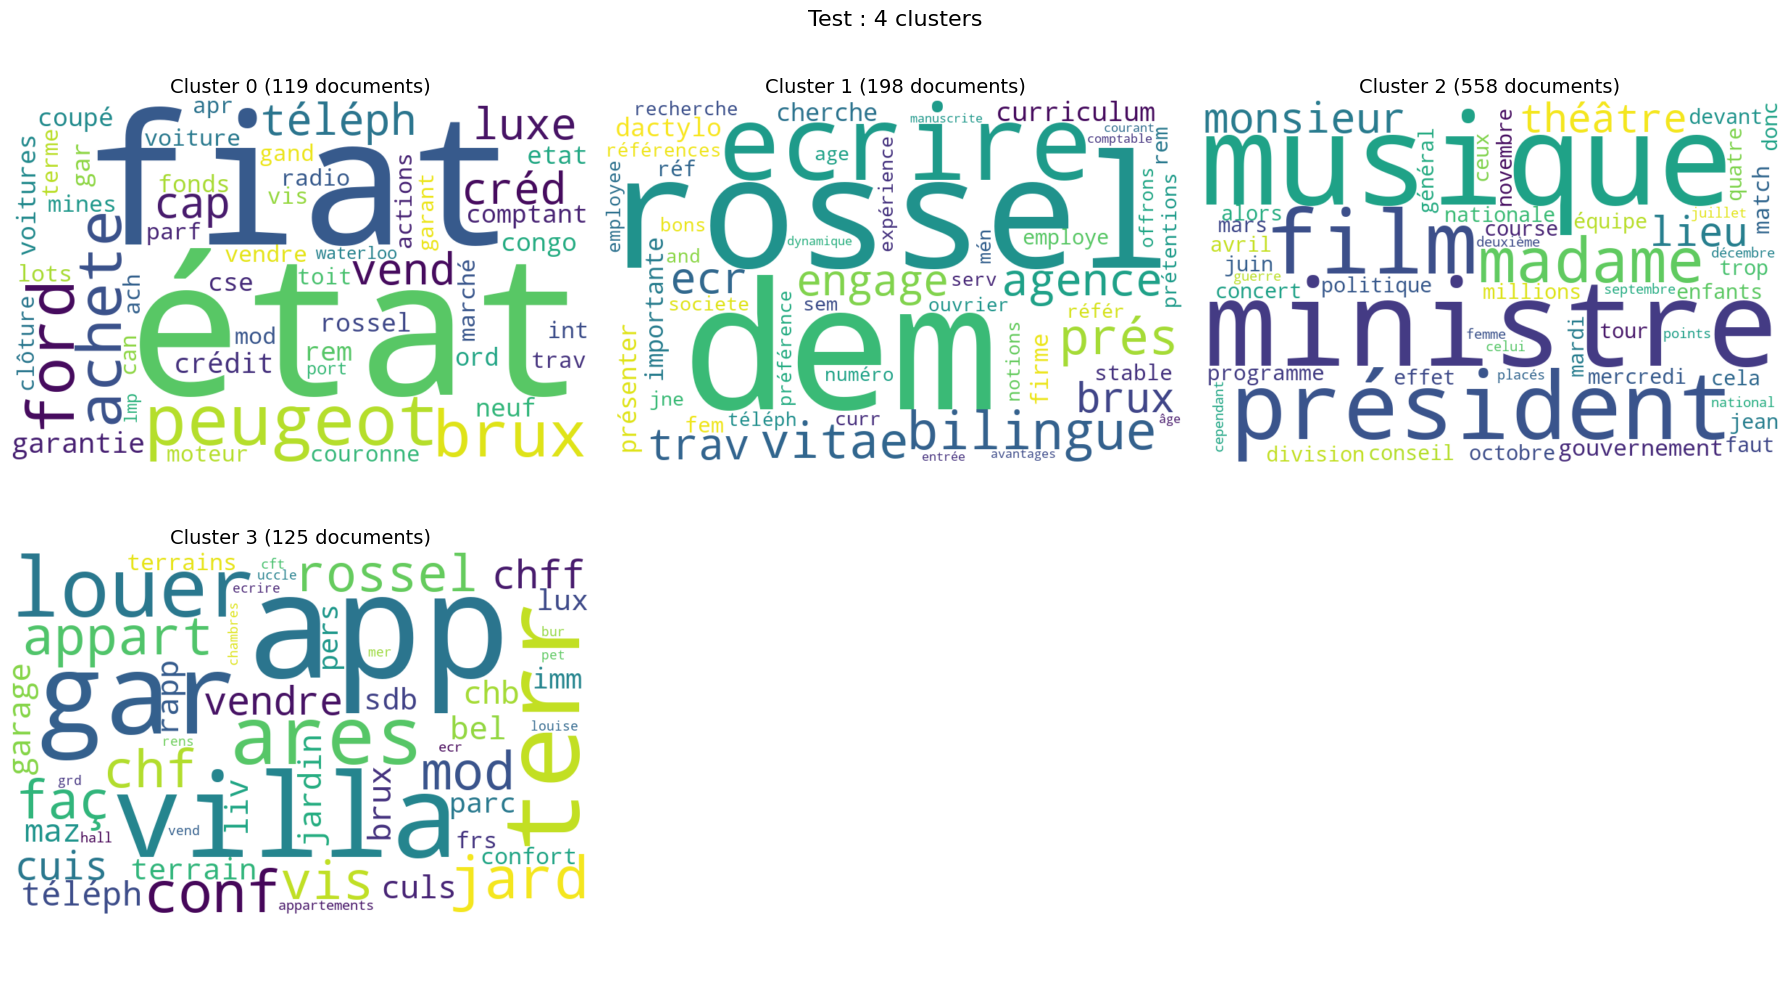

In [39]:
# Test complémentaire : 4 clusters, pour le comparer à notre choix de 9
modele4 = KMeans(n_clusters=4, random_state=42, n_init=10)
modele4.fit(tfidf_vectors)

taille = collections.Counter(modele4.labels_)
for c in range(4):
    top = modele4.cluster_centers_[c].argsort()[::-1][:40]
    # Garder seulement les vrais mots, comme pour les nuages
    mots_c = [mots[i] for i in top if mots[i].isalpha() and len(mots[i]) > 2][:10]
    print(f"Cluster {c} ({taille[c]} docs) : {', '.join(mots_c)}")

nuages_clusters(modele4, 4, "Test : 4 clusters")

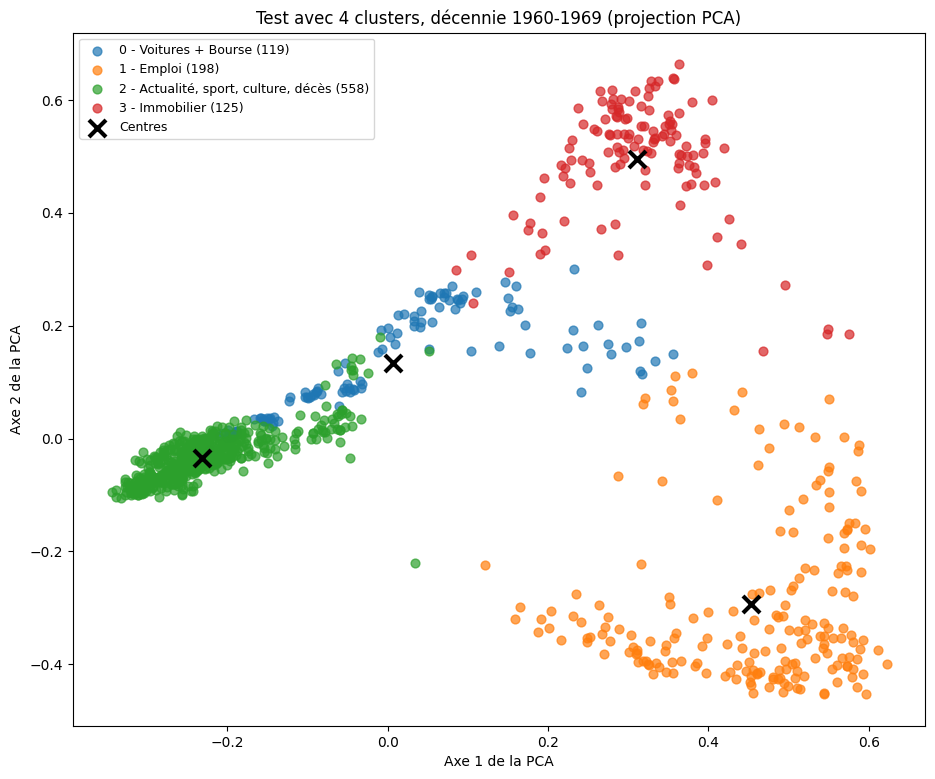

In [40]:
# Visualiser les 4 clusters du test avec la même projection PCA que pour 9 clusters
noms4 = {0: "Voitures + Bourse", 1: "Emploi", 2: "Actualité, sport, culture, décès",
         3: "Immobilier"}

etiquettes4 = modele4.labels_
centres4 = pca9.transform(modele4.cluster_centers_)

plt.figure(figsize=(11, 9))
couleurs = plt.cm.tab10.colors
for c in range(4):
    masque = etiquettes4 == c
    plt.scatter(points[masque, 0], points[masque, 1], s=40, alpha=0.7,
                color=couleurs[c], label=f"{c} - {noms4[c]} ({masque.sum()})")

# Ajouter le centre de chaque cluster
plt.scatter(centres4[:, 0], centres4[:, 1], marker="x", s=150, linewidths=3,
            color="black", label="Centres")

plt.title("Test avec 4 clusters, décennie 1960-1969 (projection PCA)")
plt.xlabel("Axe 1 de la PCA")
plt.ylabel("Axe 2 de la PCA")
plt.legend(loc="best", fontsize=9)
plt.savefig("pca_4clusters_1960.png", dpi=150, bbox_inches="tight")
plt.show()